<a href="https://colab.research.google.com/github/lucaspereira25-lps/LucasPereira-CalculoNum-rico/blob/main/Gauss.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== QUESTÃO 1: FORMA MATRICIAL ===
A matriz dos coeficientes A:
[[10. -1.  2.]
 [-1. 11. -1.]
 [ 2. -1. 10.]]

O vetor das incógnitas x:
x = [x, y, z]^T

O vetor dos termos independentes b:
[  6.  22. -10.]
------------------------------------------------------------

=== QUESTÃO 2: VERIFICAÇÃO DE DIAGONAL DOMINÂNCIA ===
Linha 1: |a_11| = 10.0 | Soma dos outros: 3.0 -> 10.0 > 3.0 (estritamente maior)
Linha 2: |a_22| = 11.0 | Soma dos outros: 2.0 -> 11.0 > 2.0 (estritamente maior)
Linha 3: |a_33| = 10.0 | Soma dos outros: 3.0 -> 10.0 > 3.0 (estritamente maior)

Conclusão: A matriz é estritamente diagonal dominante por linhas.
Relevância: Essa propriedade garante a CONVERGÊNCIA do método de Gauss-Seidel
independentemente da escolha da aproximação inicial x^(0).
------------------------------------------------------------

=== QUESTÃO 3: FÓRMULAS ITERATIVAS ===
x^(k+1) = (6 + y^(k) - 2*z^(k)) / 10
y^(k+1) = (22 + x^(k+1) + z^(k)) / 11   <-- utiliza o x já atualizado
z^(k+1) = (-10 - 2*x^(

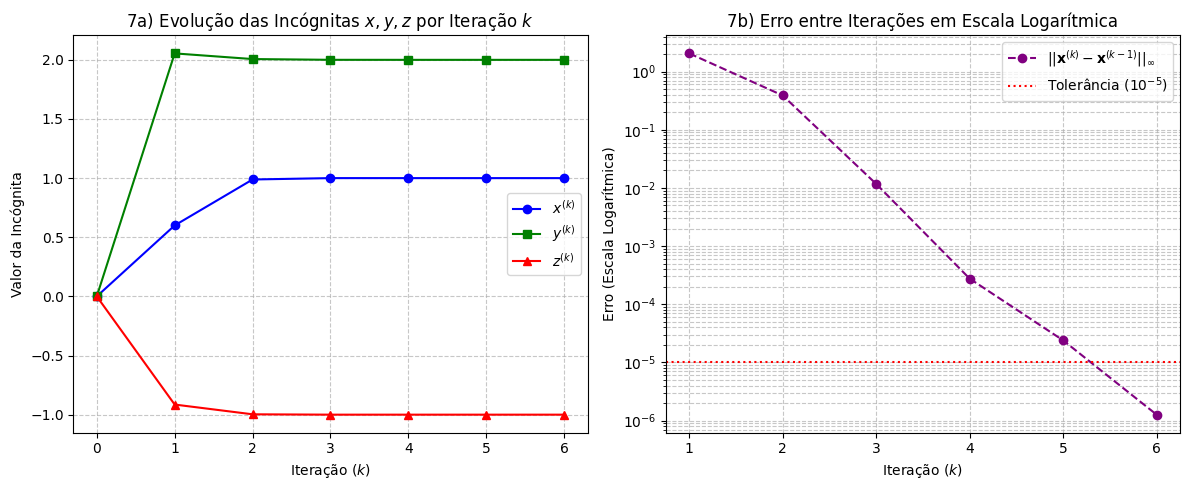

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# =============================================================================
# QUESTÃO 1: Forma Matricial Ax = b
# =============================================================================
print("=== QUESTÃO 1: FORMA MATRICIAL ===")
print("A matriz dos coeficientes A:")
A = np.array([[10, -1, 2],
              [-1, 11, -1],
              [2, -1, 10]], dtype=float)
print(A)

print("\nO vetor das incógnitas x:")
print("x = [x, y, z]^T")

print("\nO vetor dos termos independentes b:")
b = np.array([6, 22, -10], dtype=float)
print(b)
print("-" * 60)

# =============================================================================
# QUESTÃO 2: Diagonal Dominância por Linhas
# =============================================================================
print("\n=== QUESTÃO 2: VERIFICAÇÃO DE DIAGONAL DOMINÂNCIA ===")
is_dd = True
for i in range(3):
    diag = abs(A[i, i])
    soma_fora_diag = sum(abs(A[i, j]) for j in range(3) if j != i)
    status = "estritamente maior" if diag > soma_fora_diag else "não maior"
    print(f"Linha {i+1}: |a_{i+1}{i+1}| = {diag} | Soma dos outros: {soma_fora_diag} -> {diag} > {soma_fora_diag} ({status})")
    if diag <= soma_fora_diag:
        is_dd = False

print("\nConclusão: A matriz é estritamente diagonal dominante por linhas.")
print("Relevância: Essa propriedade garante a CONVERGÊNCIA do método de Gauss-Seidel")
print("independentemente da escolha da aproximação inicial x^(0).")
print("-" * 60)

# =============================================================================
# QUESTÃO 3 & 4: Fórmulas Iterativas e Cálculo das 3 Primeiras Iterações
# =============================================================================
print("\n=== QUESTÃO 3: FÓRMULAS ITERATIVAS ===")
print("x^(k+1) = (6 + y^(k) - 2*z^(k)) / 10")
print("y^(k+1) = (22 + x^(k+1) + z^(k)) / 11   <-- utiliza o x já atualizado")
print("z^(k+1) = (-10 - 2*x^(k+1) + y^(k+1)) / 10 <-- utiliza x e y atualizados")
print("-" * 60)

print("\n=== QUESTÃO 4: CÁLCULO MANUAL DAS 3 PRIMEIRAS ITERAÇÕES ===")
x_man = 0.0
y_man = 0.0
z_man = 0.0

for k in range(1, 4):
    x_new = (6 + y_man - 2 * z_man) / 10.0
    y_new = (22 + x_new + z_man) / 11.0
    z_new = (-10 - 2 * x_new + y_new) / 10.0

    print(f"\nIteração {k}:")
    print(f"  x^({k}) = (6 + {y_man:.4f} - 2*({z_man:.4f})) / 10 = {x_new:.6f}")
    print(f"  y^({k}) = (22 + {x_new:.6f} + {z_man:.4f}) / 11 = {y_new:.6f}")
    print(f"  z^({k}) = (-10 - 2*({x_new:.6f}) + {y_new:.6f}) / 10 = {z_new:.6f}")

    x_man, y_man, z_man = x_new, y_new, z_new
print("-" * 60)

# =============================================================================
# QUESTÃO 5 & 6: Implementação do Método de Gauss-Seidel e Tabela de Resultados
# =============================================================================
def gauss_seidel(A, b, x0, tol=1e-5, max_iter=100):
    n = len(b)
    x = x0.copy()
    historico = []

    # Armazena a iteração inicial k=0
    historico.append({
        'k': 0,
        'x^(k)': x[0],
        'y^(k)': x[1],
        'z^(k)': x[2],
        r'||x^(k) - x^(k-1)||_infty': '-'
    })

    for k in range(1, max_iter + 1):
        x_old = x.copy()

        for i in range(n):
            soma = sum(A[i][j] * x[j] for j in range(n) if j != i)
            x[i] = (b[i] - soma) / A[i][i]

        erro = np.max(np.abs(x - x_old))

        historico.append({
            'k': k,
            'x^(k)': x[0],
            'y^(k)': x[1],
            'z^(k)': x[2],
            r'||x^(k) - x^(k-1)||_infty': erro
        })

        if erro < tol:
            break

    return x, k, pd.DataFrame(historico)

# Aproximação inicial
x0 = np.array([0.0, 0.0, 0.0])
solucao, total_iteracoes, df_resultados = gauss_seidel(A, b, x0, tol=1e-5)

print("\n=== QUESTÃO 5: RESULTADO DA IMPLEMENTAÇÃO ===")
print(f"Número total de iterações realizadas: {total_iteracoes}")
print(f"Solução aproximada obtida: x = {solucao[0]:.6f}, y = {solucao[1]:.6f}, z = {solucao[2]:.6f}")
print("-" * 60)

print("\n=== QUESTÃO 6: TABELA COM OS RESULTADOS DAS ITERAÇÕES ===")
pd.set_option('display.float_format', lambda x: f'{x:.6f}' if isinstance(x, float) else str(x))
print(df_resultados.to_string(index=False))
print("-" * 60)

# =============================================================================
# QUESTÃO 7: Gráficos
# =============================================================================
ks = df_resultados['k'].values
xs = df_resultados['x^(k)'].values
ys = df_resultados['y^(k)'].values
zs = df_resultados['z^(k)'].values

# Erro a partir da iteração k=1
erros = df_resultados[r'||x^(k) - x^(k-1)||_infty'].values[1:].astype(float)
ks_erros = ks[1:]

plt.figure(figsize=(12, 5))

# 7a) Evolução das incógnitas x, y e z em função de k
plt.subplot(1, 2, 1)
plt.plot(ks, xs, 'o-', label=r'$x^{(k)}$', color='blue')
plt.plot(ks, ys, 's-', label=r'$y^{(k)}$', color='green')
plt.plot(ks, zs, '^-', label=r'$z^{(k)}$', color='red')
plt.title('7a) Evolução das Incógnitas $x, y, z$ por Iteração $k$')
plt.xlabel('Iteração ($k$)')
plt.ylabel('Valor da Incógnita')
plt.xticks(ks)
plt.grid(True, linestyle='--', alpha=0.7)
plt.legend()

# 7b) Erro entre iterações em escala logarítmica
plt.subplot(1, 2, 2)
plt.semilogy(ks_erros, erros, 'o--', color='purple', label=r'$||\mathbf{x}^{(k)} - \mathbf{x}^{(k-1)}||_\infty$')
plt.axhline(y=1e-5, color='r', linestyle=':', label=r'Tolerância ($10^{-5}$)')
plt.title('7b) Erro entre Iterações em Escala Logarítmica')
plt.xlabel('Iteração ($k$)')
plt.ylabel('Erro (Escala Logarítmica)')
plt.xticks(ks_erros)
plt.grid(True, which="both", linestyle='--', alpha=0.7)
plt.legend()

plt.tight_layout()
plt.show()